<a href="https://colab.research.google.com/github/BuvanAlfarezy/BuvanAlfarezy_Test3_ClusteringK-Means/blob/main/BuvanAlfarezy_Test3_ClusteringK_Means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib streamlit plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 46.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 91.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [2]:
import os
import json
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import joblib
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
BASE_DIR = Path("/content")
DATA_DIR = BASE_DIR / "earthquake_data"
ARTIFACT_DIR = BASE_DIR / "earthquake_artifacts"
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("Library siap digunakan.")
print("Folder data     :", DATA_DIR)
print("Folder artefak  :", ARTIFACT_DIR)

Library siap digunakan.
Folder data     : /content/earthquake_data
Folder artefak  : /content/earthquake_artifacts


In [3]:
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("Belum ada file yang diunggah. Unggah CSV atau ZIP dataset Kaggle terlebih dahulu.")

for filename, content in uploaded.items():
    destination = DATA_DIR / Path(filename).name
    destination.write_bytes(content)
    if destination.suffix.lower() == ".zip":
        with zipfile.ZipFile(destination, "r") as archive:
            # Ekstraksi dataset Kaggle ke folder kerja Colab.
            archive.extractall(DATA_DIR / destination.stem)
        print(f"ZIP diekstrak: {destination.name}")
    else:
        print(f"File disimpan: {destination.name}")

csv_candidates = sorted(DATA_DIR.rglob("*.csv"), key=lambda p: p.stat().st_size, reverse=True)
if not csv_candidates:
    raise FileNotFoundError(
        f"Tidak ditemukan file CSV di {DATA_DIR}. Pastikan ZIP berisi CSV atau unggah file CSV langsung."
    )

print("\nCSV yang ditemukan:")
for i, path in enumerate(csv_candidates):
    print(f"[{i}] {path} — {path.stat().st_size / 1024:.1f} KB")

# Pilihan awal: CSV dengan ukuran file terbesar. Jika file utama bukan ini,
# ganti indeksnya, misalnya CSV_PATH = csv_candidates[1].
CSV_PATH = csv_candidates[0]
print("\nCSV yang akan dibaca:", CSV_PATH)

Saving global_earthquakes_seismic.csv to global_earthquakes_seismic.csv
File disimpan: global_earthquakes_seismic.csv

CSV yang ditemukan:
[0] /content/earthquake_data/global_earthquakes_seismic.csv — 8898.7 KB

CSV yang akan dibaca: /content/earthquake_data/global_earthquakes_seismic.csv


In [4]:
try:
    df = pd.read_csv(CSV_PATH, low_memory=False)
except UnicodeDecodeError:
    df = pd.read_csv(CSV_PATH, low_memory=False, encoding="latin-1")

# Normalisasi nama kolom agar akses kolom lebih konsisten.
df.columns = [
    str(column).strip().lower().replace(" ", "_").replace("-", "_")
    for column in df.columns
]

print("Dataset berhasil dibaca.")
print("Ukuran dataset:", df.shape)
display(df.head())

Dataset berhasil dibaca.
Ukuran dataset: (10000, 25)


,id,time,latitude,longitude,depth,mag,magtype,place,status,tsunami,sig,net,nst,dmin,rms,gap,type,title,evidence_span,cot_rationale,magnitude_severity_class,focal_depth_regime,tsunami_hazard_potential,tectonic_boundary_zone,confidence_score
0,us6000u20i,1791884908205,-9.9266,118.8246,35.0,4.5,mb,"71 km SW of Tambolaka, Indonesia",reviewed,0,312,us,28,4.966,0.67,123.0,earthquake,"M 4.5 - 71 km SW of Tambolaka, Indonesia",M: 4.5 (mb) | depth: 35.0km | place: '71 km SW...,"Seismic event 'M 4.5 - 71 km SW of Tambolaka, ...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98
1,us6000u20g,1791884472899,38.5166,68.8922,10.0,4.7,mb,"9 km NE of Boshkengash, Tajikistan",reviewed,0,340,us,64,1.821,0.70,62.0,earthquake,"M 4.7 - 9 km NE of Boshkengash, Tajikistan",M: 4.7 (mb) | depth: 10.0km | place: '9 km NE ...,"Seismic event 'M 4.7 - 9 km NE of Boshkengash,...",moderate,shallow_crustal,inland_negligible,alpide_himalayan_belt,0.98
2,us6000u207,1791880708325,-28.5560,-12.5205,10.0,5.3,mb,southern Mid-Atlantic Ridge,reviewed,0,432,us,37,27.968,1.03,63.0,earthquake,M 5.3 - southern Mid-Atlantic Ridge,M: 5.3 (mb) | depth: 10.0km | place: 'southern...,Seismic event 'M 5.3 - southern Mid-Atlantic R...,moderate,shallow_crustal,inland_negligible,mid_ocean_ridge_divergent,0.98
3,us6000u1zh,1791873544944,7.7685,-81.4531,10.0,4.7,mb,"14 km WNW of Río Grande, Panama",reviewed,0,340,us,37,2.117,0.80,140.0,earthquake,"M 4.7 - 14 km WNW of Río Grande, Panama",M: 4.7 (mb) | depth: 10.0km | place: '14 km WN...,Seismic event 'M 4.7 - 14 km WNW of Río Grande...,moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98
4,us6000u1zc,1791871284155,19.6853,120.7047,10.0,4.7,mb,"124 km N of Pagudpud, Philippines",reviewed,0,340,us,42,3.136,0.95,132.0,earthquake,"M 4.7 - 124 km N of Pagudpud, Philippines",M: 4.7 (mb) | depth: 10.0km | place: '124 km N...,"Seismic event 'M 4.7 - 124 km N of Pagudpud, P...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98


In [5]:
print("Jumlah baris :", f"{df.shape[0]:,}")
print("Jumlah kolom :", df.shape[1])
print("\nTipe data tiap kolom:")
display(df.dtypes.astype(str).rename("dtype").to_frame())
print("\nRingkasan statistik numerik:")
display(df.describe(include=[np.number]).T)
print("\nRingkasan kolom secara lengkap:")
df.info()

Jumlah baris : 10,000
Jumlah kolom : 25

Tipe data tiap kolom:


,dtype
id,object
time,int64
latitude,float64
longitude,float64
depth,float64
mag,float64
magtype,object
place,object
status,object
tsunami,int64



Ringkasan statistik numerik:


,count,mean,std,min,25%,50%,75%,max
time,10000.0,1.771917e+12,1.169027e+10,1.753890e+12,1.760858e+12,1.772140e+12,1.782527e+12,1.791885e+12
latitude,10000.0,7.828576e+00,3.190944e+01,-6.746860e+01,-1.544930e+01,5.194650e+00,3.838593e+01,8.506430e+01
longitude,10000.0,6.165019e+01,1.164409e+02,-1.799970e+02,-3.262930e+01,1.250271e+02,1.522645e+02,1.799899e+02
depth,10000.0,5.616578e+01,1.015771e+02,0.000000e+00,1.000000e+01,1.100000e+01,5.699325e+01,6.695560e+02
mag,10000.0,4.812037e+00,3.672658e-01,4.500000e+00,4.500000e+00,4.700000e+00,5.000000e+00,7.800000e+00
tsunami,10000.0,8.400000e-03,9.127033e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
sig,10000.0,3.625626e+02,8.791559e+01,3.120000e+02,3.130000e+02,3.400000e+02,3.850000e+02,2.910000e+03
nst,10000.0,6.678190e+01,4.685581e+01,0.000000e+00,3.400000e+01,5.500000e+01,8.500000e+01,5.660000e+02
dmin,10000.0,4.128023e+00,5.263083e+00,0.000000e+00,1.498000e+00,2.493500e+00,4.651000e+00,5.530700e+01
rms,10000.0,7.624708e-01,2.199221e-01,1.200000e-01,6.100000e-01,7.400000e-01,9.000000e-01,3.900000e+00



Ringkasan kolom secara lengkap:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        10000 non-null  object 
 1   time                      10000 non-null  int64  
 2   latitude                  10000 non-null  float64
 3   longitude                 10000 non-null  float64
 4   depth                     10000 non-null  float64
 5   mag                       10000 non-null  float64
 6   magtype                   10000 non-null  object 
 7   place                     10000 non-null  object 
 8   status                    10000 non-null  object 
 9   tsunami                   10000 non-null  int64  
 10  sig                       10000 non-null  int64  
 11  net                       10000 non-null  object 
 12  nst                       10000 non-null  int64  
 13  dmin                      100

In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
}).sort_values("missing_percent", ascending=False)

display(missing_summary)
print("Jumlah baris duplikat persis:", int(df.duplicated().sum()))
if "id" in df.columns:
    print("Jumlah ID kosong:", int(df["id"].isna().sum()))
    print("Jumlah ID duplikat non-kosong:", int((df["id"].notna() & df["id"].duplicated()).sum()))

,missing_count,missing_percent,dtype
id,0,0.0,object
time,0,0.0,int64
latitude,0,0.0,float64
longitude,0,0.0,float64
depth,0,0.0,float64
mag,0,0.0,float64
magtype,0,0.0,object
place,0,0.0,object
status,0,0.0,object
tsunami,0,0.0,int64


Jumlah baris duplikat persis: 0
Jumlah ID kosong: 0
Jumlah ID duplikat non-kosong: 0


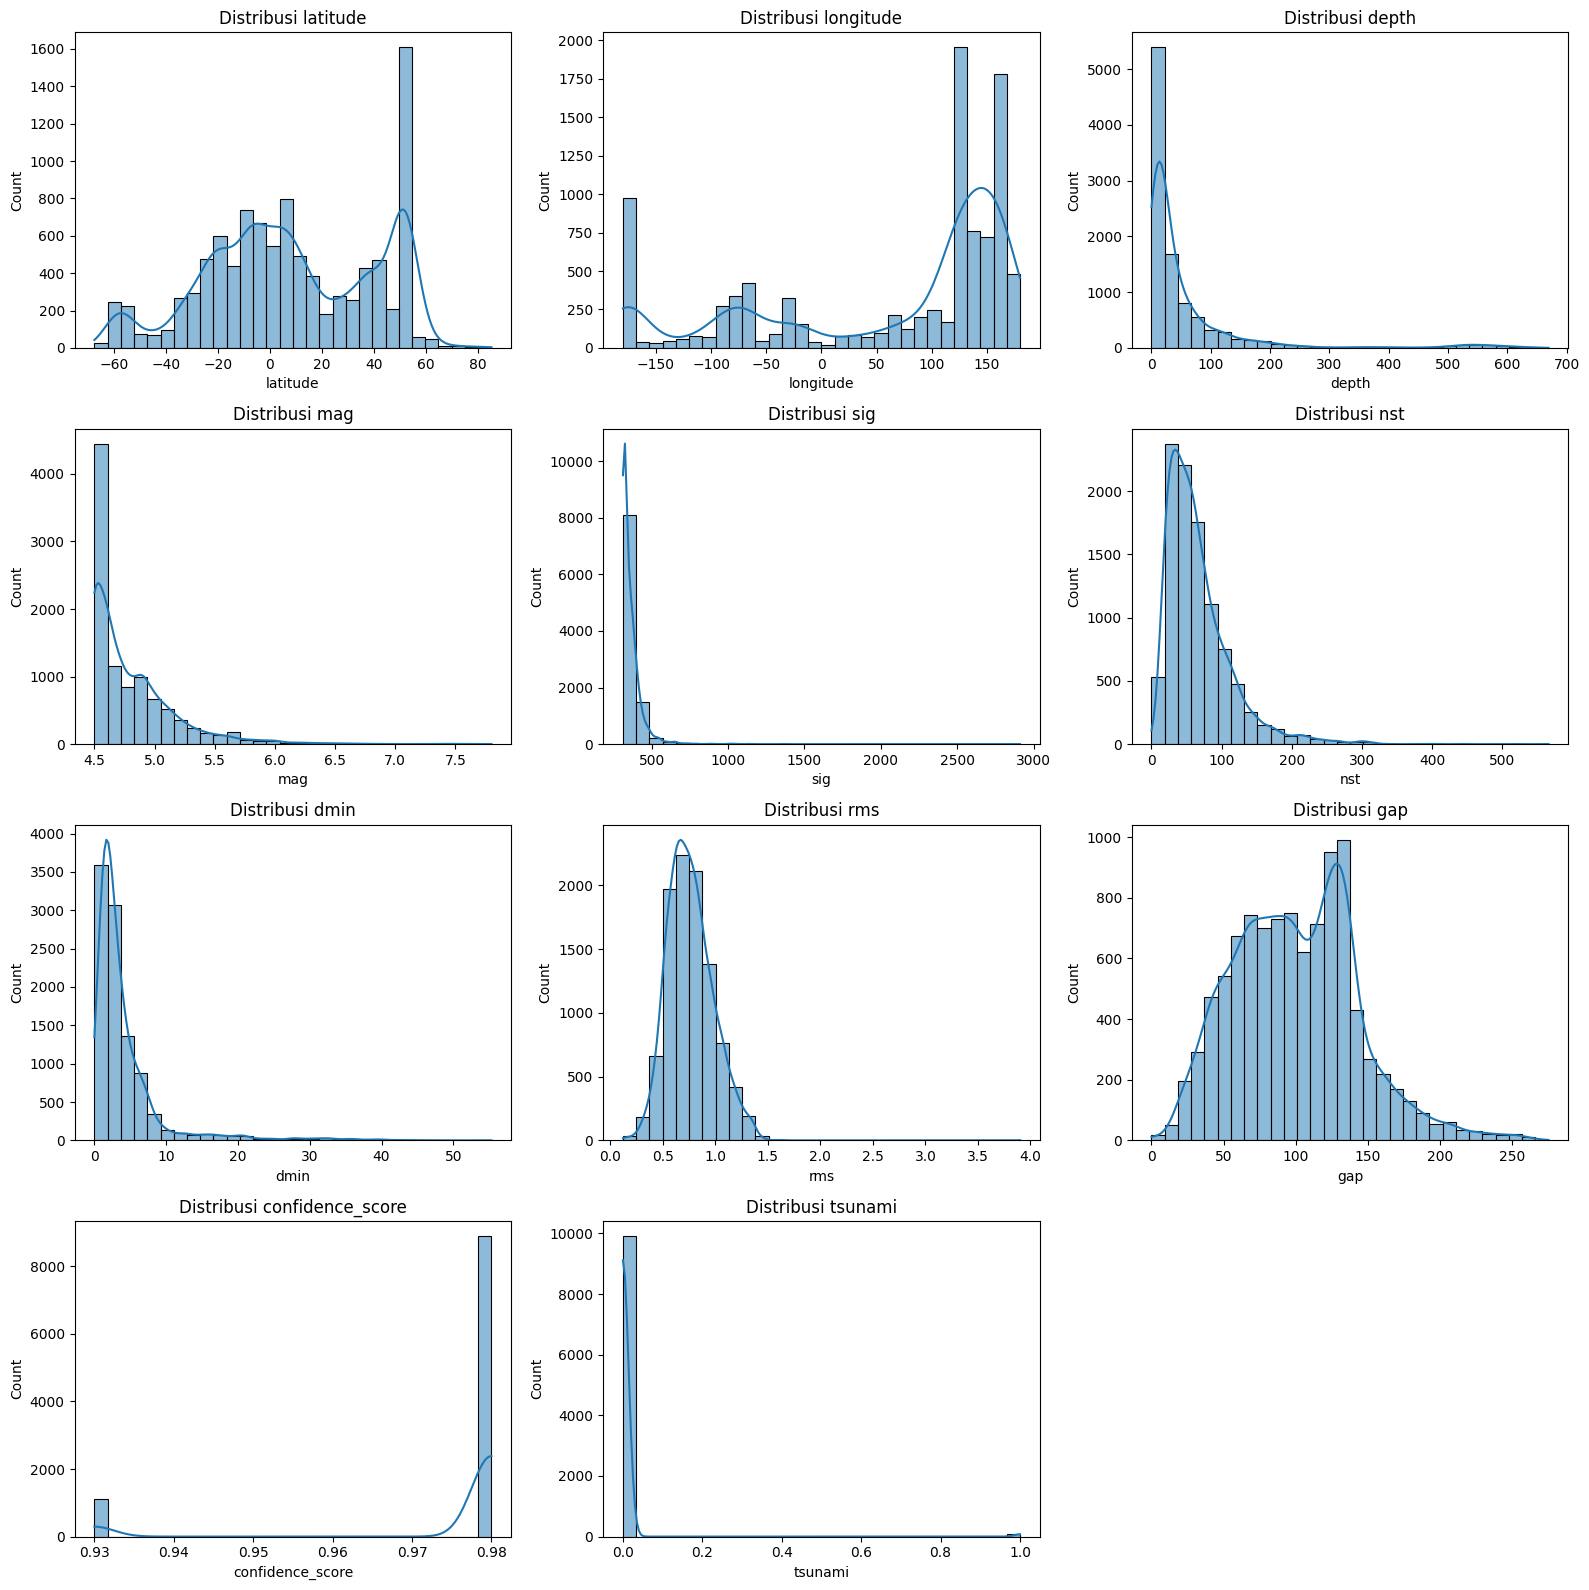

Interpretasi: histogram memperlihatkan rentang nilai, kemencengan distribusi, dan kemungkinan nilai ekstrem pada fitur seismik. Nilai ekstrem tidak langsung dihapus karena gempa kuat atau dalam dapat merupakan kejadian nyata.


In [7]:
NUMERIC_CANDIDATES = [
    "latitude", "longitude", "depth", "mag", "sig", "nst",
    "dmin", "rms", "gap", "confidence_score", "tsunami"
]

for column in NUMERIC_CANDIDATES:
    if column in df.columns:
        if column == "tsunami":
            df[column] = df[column].replace({
                True: 1, False: 0, "True": 1, "False": 0,
                "true": 1, "false": 0, "yes": 1, "no": 0,
                "YES": 1, "NO": 0
            })
        df[column] = pd.to_numeric(df[column], errors="coerce")

eda_numeric = [c for c in NUMERIC_CANDIDATES if c in df.columns and df[c].notna().any()]
if not eda_numeric:
    raise ValueError("Tidak ditemukan fitur numerik seismik yang sesuai. Periksa nama kolom CSV.")

ncols = 3
nrows = int(np.ceil(len(eda_numeric) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.array(axes).reshape(-1)
for ax, column in zip(axes, eda_numeric):
    sns.histplot(df[column].dropna(), kde=True, ax=ax, bins=30)
    ax.set_title(f"Distribusi {column}")
    ax.set_xlabel(column)
for ax in axes[len(eda_numeric):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

print("Interpretasi: histogram memperlihatkan rentang nilai, kemencengan distribusi, dan kemungkinan nilai ekstrem pada fitur seismik. Nilai ekstrem tidak langsung dihapus karena gempa kuat atau dalam dapat merupakan kejadian nyata.")

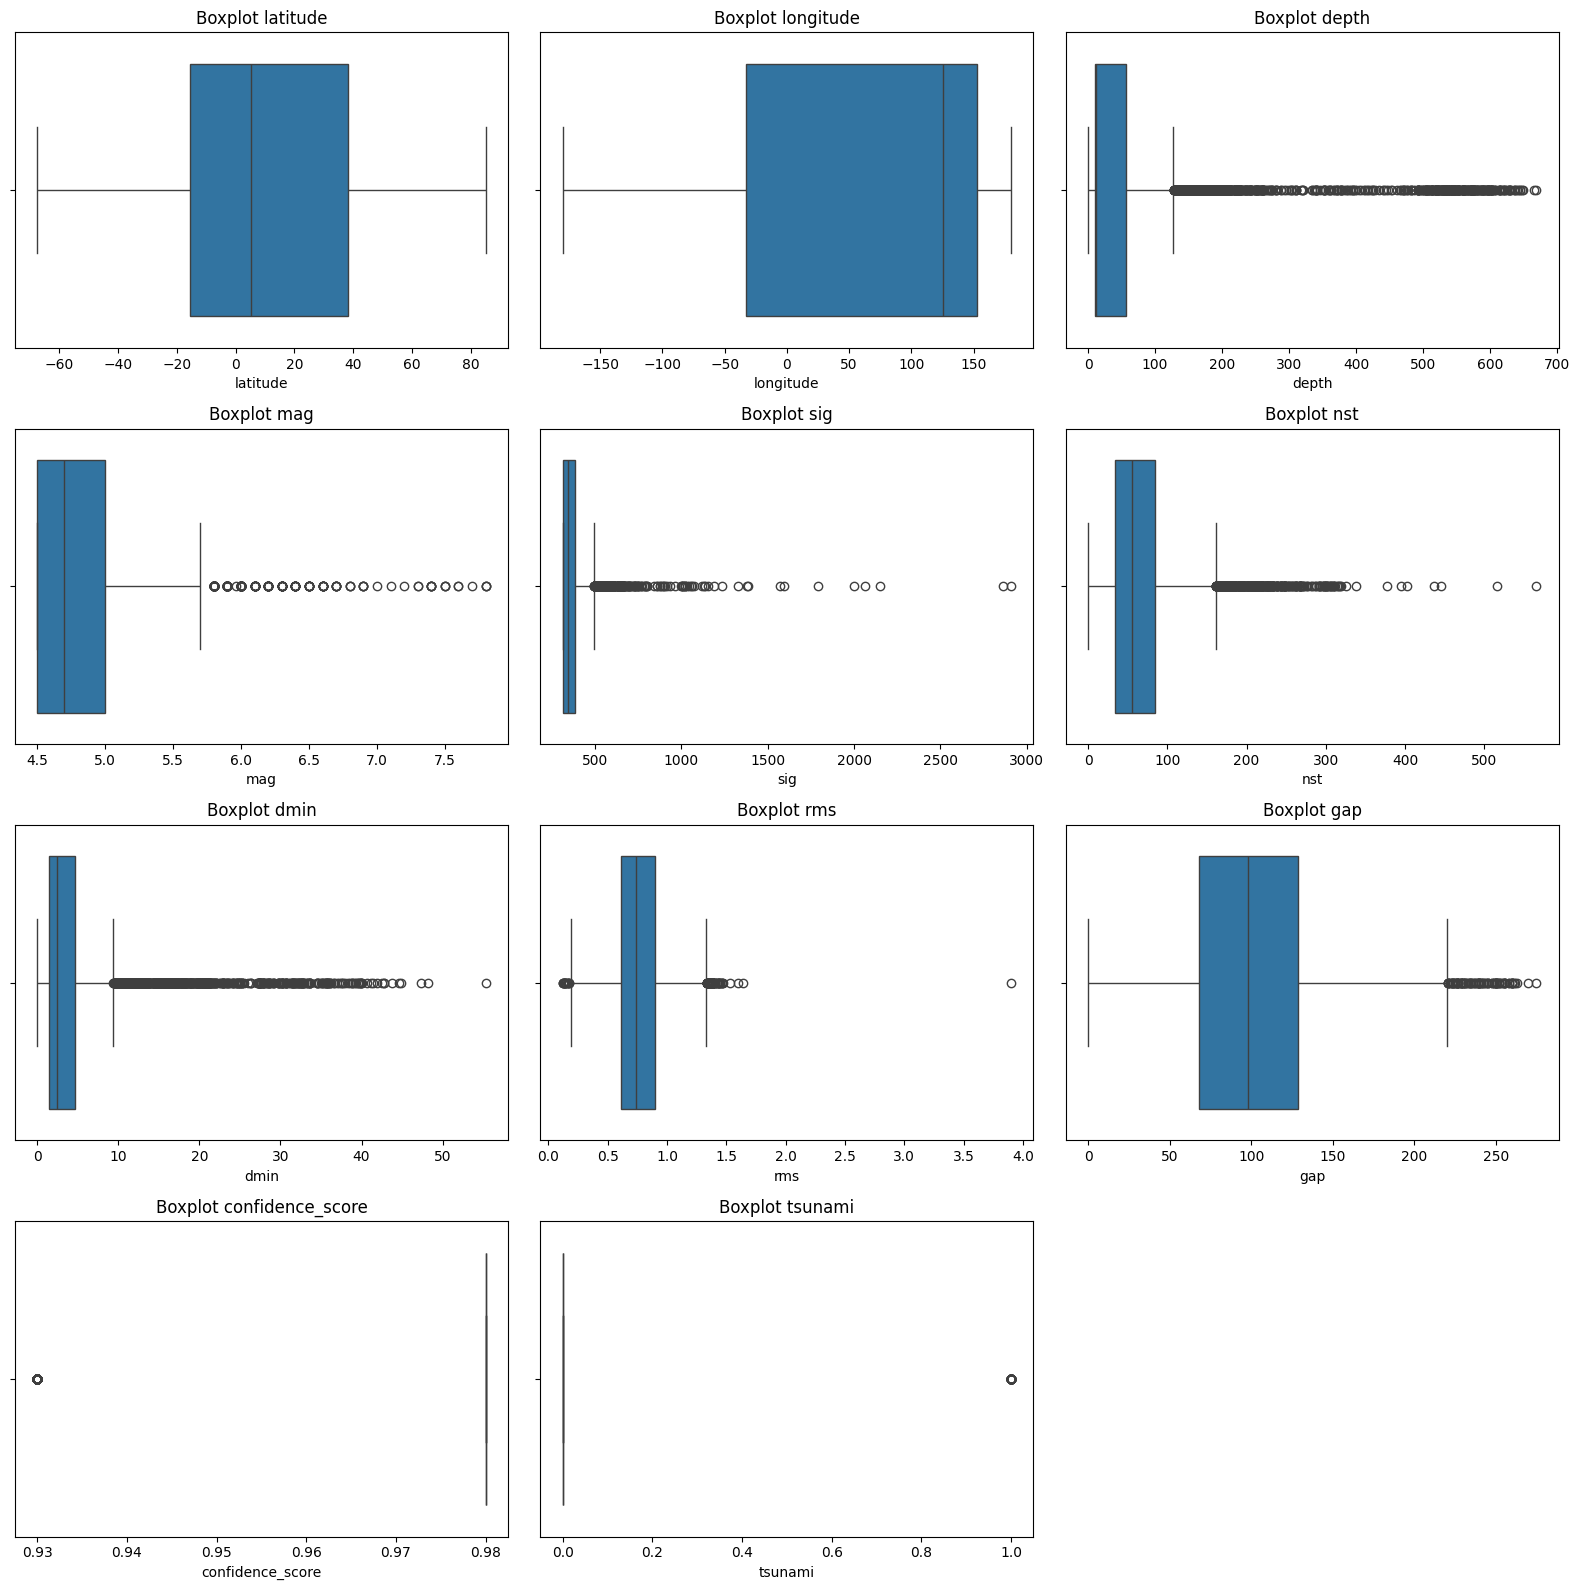

Interpretasi: titik yang jauh dari rentang utama dapat menjadi kandidat pemeriksaan, tetapi tidak otomatis dianggap kesalahan. Pada data gempa, nilai ekstrem dapat memiliki makna seismik.


In [8]:
ncols = 3
nrows = int(np.ceil(len(eda_numeric) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.array(axes).reshape(-1)
for ax, column in zip(axes, eda_numeric):
    sns.boxplot(x=df[column], ax=ax)
    ax.set_title(f"Boxplot {column}")
for ax in axes[len(eda_numeric):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()
print("Interpretasi: titik yang jauh dari rentang utama dapat menjadi kandidat pemeriksaan, tetapi tidak otomatis dianggap kesalahan. Pada data gempa, nilai ekstrem dapat memiliki makna seismik.")

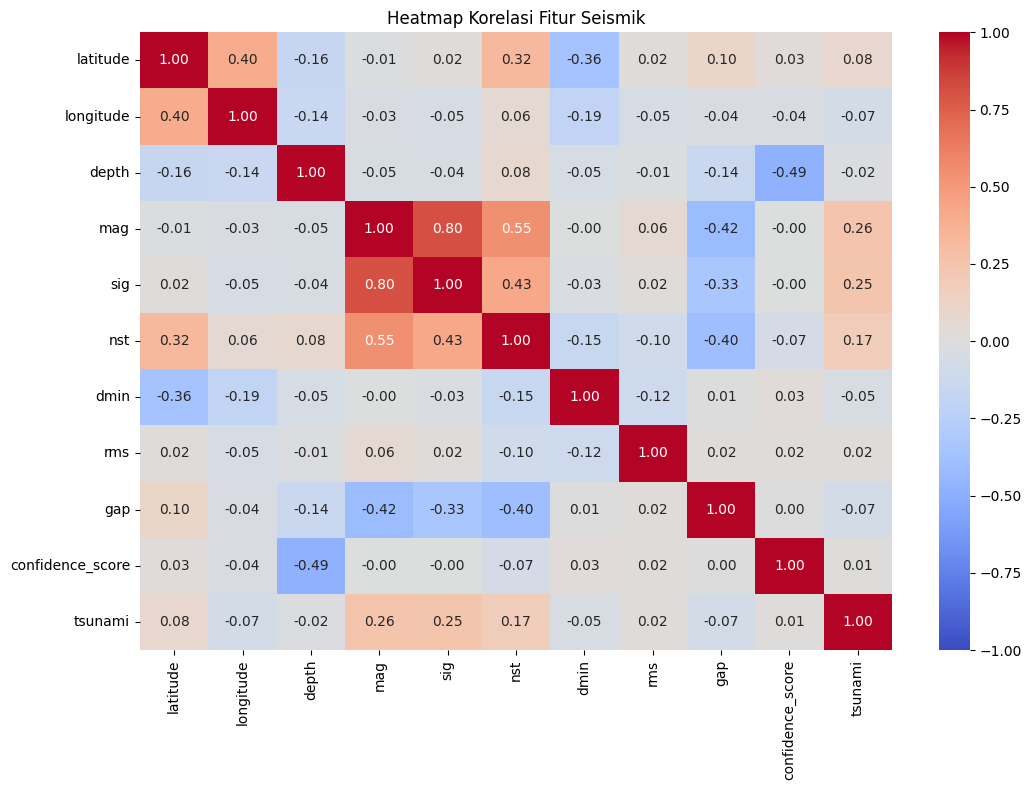

,latitude,longitude,depth,mag,sig,nst,dmin,rms,gap,confidence_score,tsunami
latitude,1.000,0.401,-0.161,-0.013,0.017,0.324,-0.362,0.023,0.104,0.028,0.085
longitude,0.401,1.000,-0.145,-0.034,-0.054,0.062,-0.188,-0.053,-0.038,-0.038,-0.071
depth,-0.161,-0.145,1.000,-0.046,-0.041,0.077,-0.052,-0.012,-0.139,-0.490,-0.020
mag,-0.013,-0.034,-0.046,1.000,0.805,0.550,-0.005,0.059,-0.418,-0.003,0.257
sig,0.017,-0.054,-0.041,0.805,1.000,0.425,-0.026,0.021,-0.328,-0.000,0.246
nst,0.324,0.062,0.077,0.550,0.425,1.000,-0.152,-0.100,-0.404,-0.069,0.174
dmin,-0.362,-0.188,-0.052,-0.005,-0.026,-0.152,1.000,-0.117,0.005,0.028,-0.046
rms,0.023,-0.053,-0.012,0.059,0.021,-0.100,-0.117,1.000,0.016,0.022,0.021
gap,0.104,-0.038,-0.139,-0.418,-0.328,-0.404,0.005,0.016,1.000,0.005,-0.074
confidence_score,0.028,-0.038,-0.490,-0.003,-0.000,-0.069,0.028,0.022,0.005,1.000,0.011


Interpretasi: korelasi mendekati +1 menunjukkan hubungan linear positif, mendekati -1 menunjukkan hubungan linear negatif, dan mendekati 0 menunjukkan hubungan linear yang lemah. Korelasi bukan bukti sebab-akibat.


In [9]:
eda_corr_cols = [c for c in eda_numeric if df[c].nunique(dropna=True) > 1]
correlation_matrix = df[eda_corr_cols].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Heatmap Korelasi Fitur Seismik")
plt.tight_layout()
plt.show()

display(correlation_matrix.round(3))
print("Interpretasi: korelasi mendekati +1 menunjukkan hubungan linear positif, mendekati -1 menunjukkan hubungan linear negatif, dan mendekati 0 menunjukkan hubungan linear yang lemah. Korelasi bukan bukti sebab-akibat.")

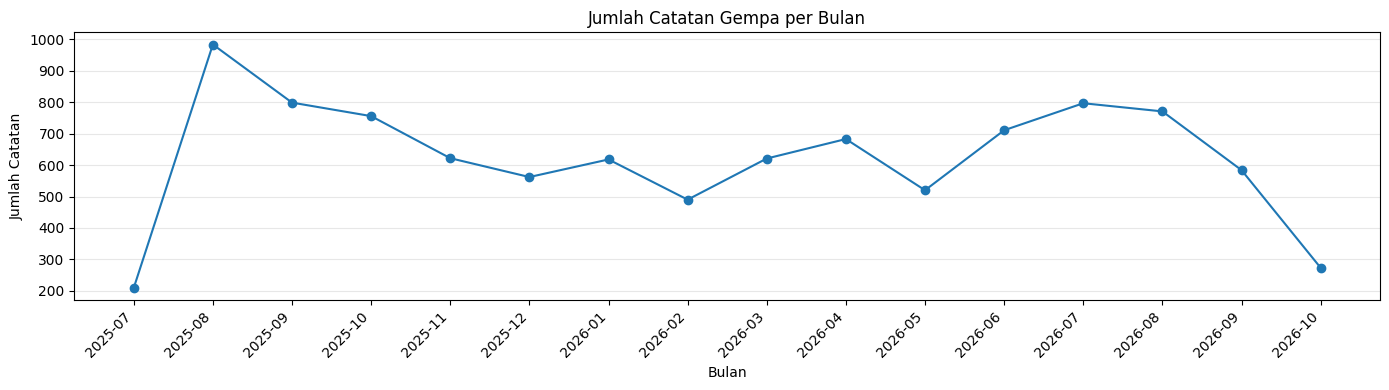

Rentang waktu: 2025-07-30 15:41:08.273000+00:00 sampai 2026-10-13 09:48:28.205000+00:00
Jumlah bulan terdeteksi: 16


,Jumlah Catatan
Bulan,
2025-07,209
2025-08,984
2025-09,799
2025-10,756
2025-11,622
2025-12,562
2026-01,618
2026-02,490
2026-03,621


In [10]:
# Konversi Unix timestamp milidetik menjadi datetime
time_numeric = pd.to_numeric(df["time"], errors="coerce")

time_parsed = pd.to_datetime(
    time_numeric,
    unit="ms",
    errors="coerce",
    utc=True
)

# Ambil data tanggal yang berhasil dikonversi
valid_times = time_parsed.dropna()

if not valid_times.empty:

    # Kelompokkan data berdasarkan tahun dan bulan
    month_labels = valid_times.dt.strftime("%Y-%m")

    time_counts = (
        month_labels.value_counts()
        .sort_index()
        .rename_axis("Bulan")
    )

    # Visualisasi
    plt.figure(figsize=(14, 4))

    plt.plot(
        time_counts.index,
        time_counts.values,
        marker="o"
    )

    plt.title("Jumlah Catatan Gempa per Bulan")
    plt.xlabel("Bulan")
    plt.ylabel("Jumlah Catatan")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("Rentang waktu:",
          valid_times.min(), "sampai", valid_times.max())

    print("Jumlah bulan terdeteksi:", len(time_counts))

    display(
        time_counts.rename("Jumlah Catatan").to_frame()
    )

else:
    print("Kolom time tidak dapat dikonversi menjadi tanggal.")


In [11]:
# Hapus duplikasi menggunakan ID bila tersedia; jika tidak, gunakan seluruh baris.
rows_before = len(df)
if "id" in df.columns:
    # Duplikasi ID hanya dihitung untuk ID yang tidak kosong; baris dengan ID kosong
    # tidak langsung disatukan hanya karena semuanya memiliki nilai ID NaN.
    duplicate_id_mask = df["id"].notna() & df["id"].duplicated(keep="first")
    df_work = df.loc[~duplicate_id_mask].drop_duplicates().copy()
else:
    df_work = df.drop_duplicates().copy()
print(f"Baris sebelum penghapusan duplikasi: {rows_before:,}")
print(f"Baris setelah penghapusan duplikasi: {len(df_work):,}")

feature_candidates = [c for c in NUMERIC_CANDIDATES if c in df_work.columns]
if len(feature_candidates) < 2:
    raise ValueError(
        "Kurang dari 2 fitur kandidat ditemukan. Pastikan CSV memiliki kolom numerik seperti latitude, longitude, depth, atau mag."
    )

for column in feature_candidates:
    if column == "tsunami":
        df_work[column] = df_work[column].replace({
            True: 1, False: 0, "True": 1, "False": 0,
            "true": 1, "false": 0, "yes": 1, "no": 0,
            "YES": 1, "NO": 0
        })
    df_work[column] = pd.to_numeric(df_work[column], errors="coerce")

df_work[feature_candidates] = df_work[feature_candidates].replace([np.inf, -np.inf], np.nan)
# Baris yang seluruh fitur kandidatnya kosong tidak dapat digunakan untuk clustering.
valid_row_mask = df_work[feature_candidates].notna().any(axis=1)
df_work = df_work.loc[valid_row_mask].copy()

# Buang fitur tanpa variasi / seluruhnya kosong karena tidak membantu membedakan cluster.
feature_columns = [
    c for c in feature_candidates
    if df_work[c].notna().any() and df_work[c].nunique(dropna=True) > 1
]
if len(feature_columns) < 2:
    raise ValueError(f"Fitur bervariasi yang tersisa kurang dari 2: {feature_columns}")

X_raw = df_work[feature_columns].copy()
feature_medians = X_raw.median(numeric_only=True)
X_filled = X_raw.fillna(feature_medians)

# Baris dengan beberapa nilai kosong tetap dipertahankan dan diimputasi median.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filled)

print("===== RINGKASAN PRA-PEMROSESAN =====")
print("Jumlah data siap clustering:", f"{len(X_filled):,}")
print("Jumlah fitur:", len(feature_columns))
print("Fitur yang digunakan:", feature_columns)
print("\nNilai median yang digunakan untuk imputasi:")
display(feature_medians.to_frame("median_imputasi"))
print("\nJumlah nilai kosong sebelum imputasi:")
display(X_raw.isna().sum().rename("missing_before_imputation").to_frame())
print("\nBentuk matriks sesudah standardisasi:", X_scaled.shape)

Baris sebelum penghapusan duplikasi: 10,000
Baris setelah penghapusan duplikasi: 10,000
===== RINGKASAN PRA-PEMROSESAN =====
Jumlah data siap clustering: 10,000
Jumlah fitur: 11
Fitur yang digunakan: ['latitude', 'longitude', 'depth', 'mag', 'sig', 'nst', 'dmin', 'rms', 'gap', 'confidence_score', 'tsunami']

Nilai median yang digunakan untuk imputasi:


,median_imputasi
latitude,5.19465
longitude,125.02710
depth,11.00000
mag,4.70000
sig,340.00000
nst,55.00000
dmin,2.49350
rms,0.74000
gap,98.00000
confidence_score,0.98000



Jumlah nilai kosong sebelum imputasi:


,missing_before_imputation
latitude,0
longitude,0
depth,0
mag,0
sig,0
nst,0
dmin,0
rms,0
gap,0
confidence_score,0



Bentuk matriks sesudah standardisasi: (10000, 11)


In [12]:
preprocessed_df = df_work.copy()
preprocessed_df[feature_columns] = X_filled
preprocessed_path = ARTIFACT_DIR / "earthquake_preprocessed.csv"
preprocessed_df.to_csv(preprocessed_path, index=False)
print("Dataset siap clustering disimpan di:", preprocessed_path)

Dataset siap clustering disimpan di: /content/earthquake_artifacts/earthquake_preprocessed.csv


,k,inertia,silhouette_score
0,2,94966.0635,0.2331
1,3,83244.2041,0.2658
2,4,74096.1810,0.2253
3,5,64161.7731,0.2244
4,6,58459.3069,0.2221
5,7,54837.1068,0.1609
6,8,50227.8211,0.1833
7,9,47288.3050,0.1837
8,10,44901.9401,0.1801


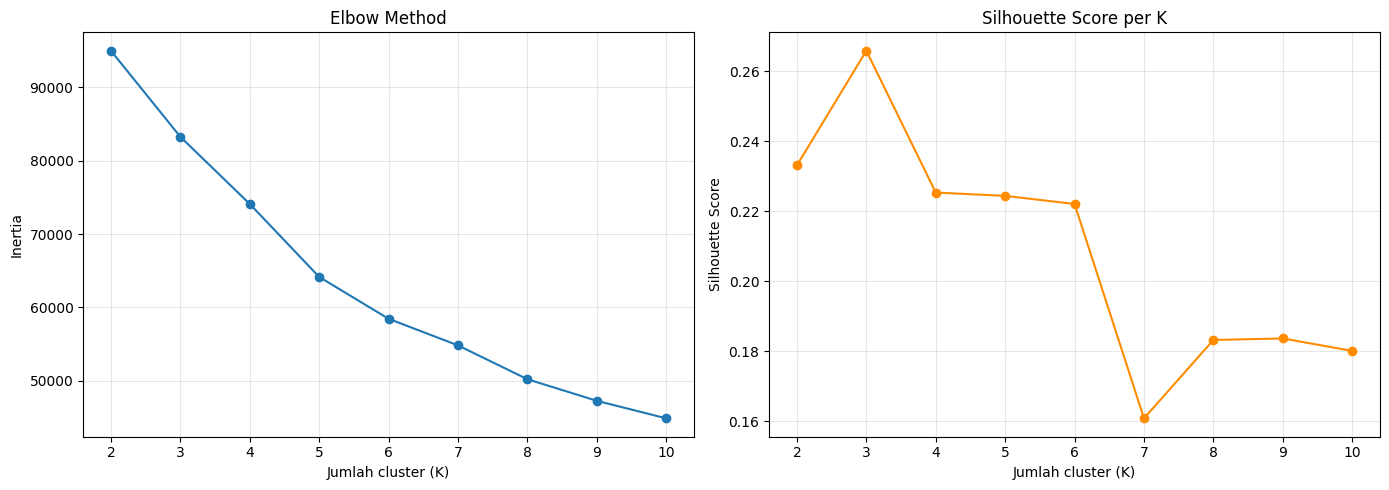

K rekomendasi berdasarkan Silhouette Score: 3
Catatan: validasi visual elbow tetap diperlukan; nilai silhouette tertinggi bukan jaminan cluster paling bermakna secara domain.


In [13]:
if X_scaled.shape[0] < 3:
    raise ValueError("Dataset harus memiliki setidaknya 3 baris valid untuk evaluasi K-Means.")

k_values = list(range(2, min(10, len(X_scaled) - 1) + 1))
search_rows = []
# Untuk menjaga waktu komputasi, silhouette dihitung pada sampel maksimal 2.500 baris oleh sklearn.
silhouette_sample_size = min(2500, len(X_scaled))

for k in k_values:
    candidate_model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    candidate_labels = candidate_model.fit_predict(X_scaled)
    try:
        sil = silhouette_score(
            X_scaled,
            candidate_labels,
            sample_size=silhouette_sample_size,
            random_state=RANDOM_STATE
        )
    except ValueError as exc:
        print(f"Silhouette gagal untuk K={k}: {exc}")
        sil = np.nan
    search_rows.append({
        "k": k,
        "inertia": float(candidate_model.inertia_),
        "silhouette_score": float(sil) if np.isfinite(sil) else np.nan
    })

k_results = pd.DataFrame(search_rows)
display(k_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_results["k"], k_results["inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Jumlah cluster (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(k_results["k"], k_results["silhouette_score"], marker="o", color="darkorange")
axes[1].set_title("Silhouette Score per K")
axes[1].set_xlabel("Jumlah cluster (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "elbow_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

valid_scores = k_results.dropna(subset=["silhouette_score"])
if valid_scores.empty:
    BEST_K = 3 if len(X_scaled) > 3 else 2
    print("Silhouette tidak berhasil dihitung; digunakan K awal:", BEST_K)
else:
    BEST_K = int(valid_scores.loc[valid_scores["silhouette_score"].idxmax(), "k"])
print("K rekomendasi berdasarkan Silhouette Score:", BEST_K)
print("Catatan: validasi visual elbow tetap diperlukan; nilai silhouette tertinggi bukan jaminan cluster paling bermakna secara domain.")

In [14]:
kmeans = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10)
cluster_labels_zero_based = kmeans.fit_predict(X_scaled)

# Label ditampilkan mulai dari Cluster 1 agar lebih mudah dibaca di laporan/dashboard.
cluster_labels = cluster_labels_zero_based + 1
clustered_df = df_work.copy()
clustered_df[feature_columns] = X_filled
clustered_df["cluster"] = cluster_labels

# Proyeksi PCA dua dimensi untuk visualisasi; PCA hanya untuk visual, bukan menggantikan K-Means.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_coords = pca.fit_transform(X_scaled)
clustered_df["PCA1"] = pca_coords[:, 0]
clustered_df["PCA2"] = pca_coords[:, 1]

final_inertia = float(kmeans.inertia_)
try:
    final_silhouette = float(silhouette_score(
        X_scaled, cluster_labels_zero_based,
        sample_size=min(2500, len(X_scaled)),
        random_state=RANDOM_STATE
    ))
except ValueError:
    final_silhouette = float("nan")

print("Model K-Means selesai dilatih.")
print("K terpilih:", BEST_K)
print("Inertia:", round(final_inertia, 4))
print("Silhouette Score:", round(final_silhouette, 4) if np.isfinite(final_silhouette) else "tidak tersedia")
display(clustered_df[[*feature_columns, "cluster"]].head())

Model K-Means selesai dilatih.
K terpilih: 3
Inertia: 83244.2041
Silhouette Score: 0.2658


,latitude,longitude,depth,mag,sig,nst,dmin,rms,gap,confidence_score,tsunami,cluster
0,-9.9266,118.8246,35.0,4.5,312,28,4.966,0.67,123.0,0.98,0,1
1,38.5166,68.8922,10.0,4.7,340,64,1.821,0.70,62.0,0.98,0,1
2,-28.5560,-12.5205,10.0,5.3,432,37,27.968,1.03,63.0,0.98,0,1
3,7.7685,-81.4531,10.0,4.7,340,37,2.117,0.80,140.0,0.98,0,1
4,19.6853,120.7047,10.0,4.7,340,42,3.136,0.95,132.0,0.98,0,1


In [15]:
cluster_counts = clustered_df["cluster"].value_counts().sort_index()
cluster_distribution = pd.DataFrame({
    "cluster": cluster_counts.index,
    "jumlah_data": cluster_counts.values,
    "persentase": (cluster_counts.values / len(clustered_df) * 100).round(2)
})

cluster_mean = clustered_df.groupby("cluster")[feature_columns].mean().round(4)
cluster_median = clustered_df.groupby("cluster")[feature_columns].median().round(4)
cluster_summary = cluster_mean.copy()
cluster_summary.insert(0, "jumlah_data", cluster_counts)
cluster_summary.insert(1, "persentase", (cluster_counts / len(clustered_df) * 100).round(2))

print("===== DISTRIBUSI DATA PER CLUSTER =====")
display(cluster_distribution)
print("===== RATA-RATA FITUR PER CLUSTER =====")
display(cluster_summary)
print("===== MEDIAN FITUR PER CLUSTER =====")
display(cluster_median)

===== DISTRIBUSI DATA PER CLUSTER =====


,cluster,jumlah_data,persentase
0,1,7050,70.50
1,2,1791,17.91
2,3,1159,11.59


===== RATA-RATA FITUR PER CLUSTER =====


,jumlah_data,persentase,latitude,longitude,depth,mag,sig,nst,dmin,rms,gap,confidence_score,tsunami
cluster,,,,,,,,,,,,,
1,7050,70.50,6.8522,64.1058,31.3017,4.6866,339.0862,50.4746,4.3613,0.7660,109.8288,0.9800,0.0000
2,1791,17.91,15.4371,61.7823,35.4612,5.3574,465.3763,128.8476,3.4179,0.7592,60.7619,0.9781,0.0469
3,1159,11.59,2.0103,46.5091,239.4044,4.7325,346.4875,70.0664,3.8066,0.7458,100.9008,0.9355,0.0000


===== MEDIAN FITUR PER CLUSTER =====


,latitude,longitude,depth,mag,sig,nst,dmin,rms,gap,confidence_score,tsunami
cluster,,,,,,,,,,,
1,4.9620,124.1242,10.00,4.6,326.0,46.0,2.473,0.75,110.0,0.98,0.0
2,14.2431,124.1065,12.00,5.2,432.0,115.0,2.093,0.73,52.0,0.98,0.0
3,-5.6736,126.7221,139.06,4.6,326.0,61.0,3.489,0.72,102.0,0.93,0.0


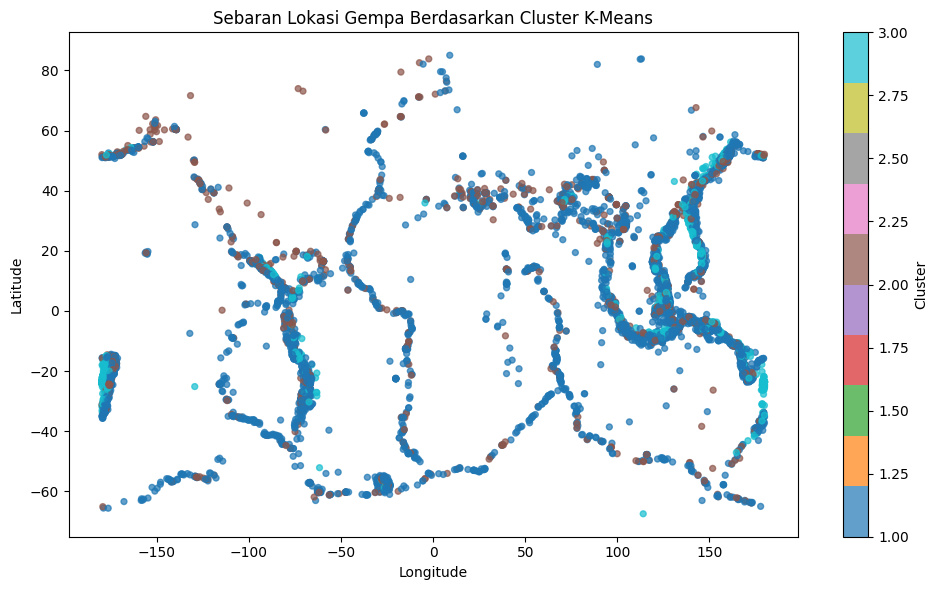

Interpretasi: plot geografis memperlihatkan apakah cluster terkonsentrasi pada wilayah tertentu. Cluster adalah hasil pengelompokan statistik, bukan batas zona tektonik resmi.


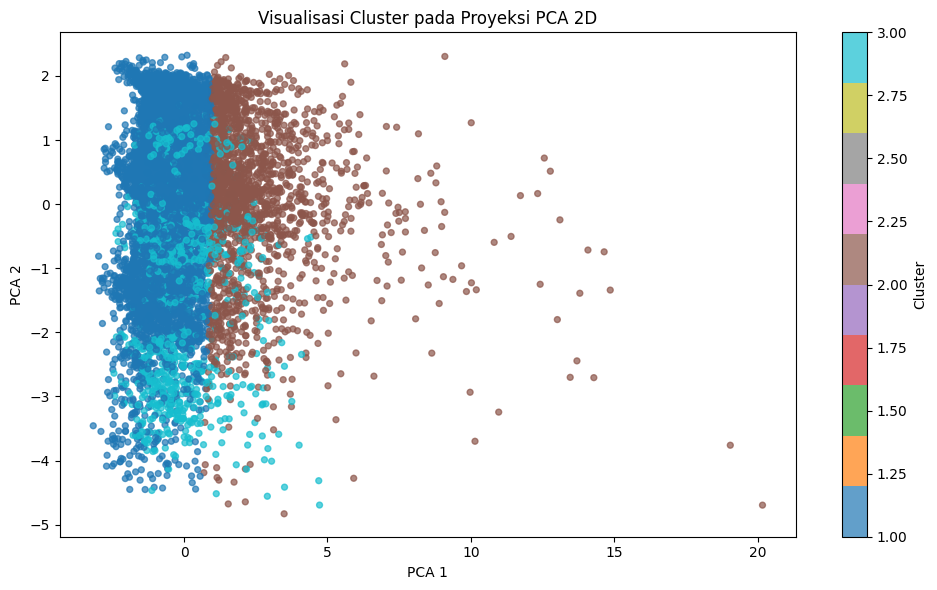

Interpretasi: PCA merangkum variasi fitur ke dua sumbu visual. Cluster yang saling tumpang tindih pada proyeksi 2D belum tentu sepenuhnya tumpang tindih pada ruang fitur berdimensi penuh.


In [16]:
if "latitude" in clustered_df.columns and "longitude" in clustered_df.columns:
    plt.figure(figsize=(10, 6))
    scatter = plt.scatter(
        clustered_df["longitude"], clustered_df["latitude"],
        c=clustered_df["cluster"], cmap="tab10", s=18, alpha=0.7
    )
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("Sebaran Lokasi Gempa Berdasarkan Cluster K-Means")
    plt.colorbar(scatter, label="Cluster")
    plt.tight_layout()
    plt.savefig(ARTIFACT_DIR / "cluster_geographic.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Interpretasi: plot geografis memperlihatkan apakah cluster terkonsentrasi pada wilayah tertentu. Cluster adalah hasil pengelompokan statistik, bukan batas zona tektonik resmi.")
else:
    print("Latitude/longitude tidak lengkap; plot geografis dilewati.")

plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    clustered_df["PCA1"], clustered_df["PCA2"],
    c=clustered_df["cluster"], cmap="tab10", s=18, alpha=0.7
)
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Visualisasi Cluster pada Proyeksi PCA 2D")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "cluster_pca.png", dpi=150, bbox_inches="tight")
plt.show()
print("Interpretasi: PCA merangkum variasi fitur ke dua sumbu visual. Cluster yang saling tumpang tindih pada proyeksi 2D belum tentu sepenuhnya tumpang tindih pada ruang fitur berdimensi penuh.")

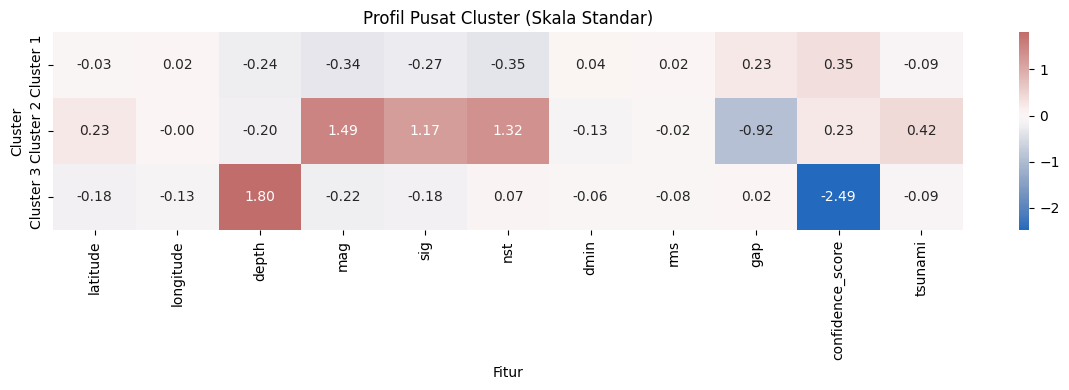

Interpretasi: warna/angka menunjukkan fitur yang relatif lebih tinggi atau lebih rendah dalam setiap pusat cluster dibandingkan rata-rata data. Ini membantu membandingkan karakteristik cluster, bukan menunjukkan kausalitas.


In [17]:
# Pusat cluster K-Means berada pada skala standar; nilai positif berarti di atas rata-rata fitur,
# dan nilai negatif berarti di bawah rata-rata fitur setelah standarisasi.
centers_df = pd.DataFrame(kmeans.cluster_centers_, columns=feature_columns, index=[f"Cluster {i+1}" for i in range(BEST_K)])
plt.figure(figsize=(max(10, len(feature_columns) * 1.1), max(4, BEST_K * 0.8)))
sns.heatmap(centers_df, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Profil Pusat Cluster (Skala Standar)")
plt.xlabel("Fitur")
plt.ylabel("Cluster")
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "cluster_centers_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Interpretasi: warna/angka menunjukkan fitur yang relatif lebih tinggi atau lebih rendah dalam setiap pusat cluster dibandingkan rata-rata data. Ini membantu membandingkan karakteristik cluster, bukan menunjukkan kausalitas.")

In [18]:
clustered_csv_path = ARTIFACT_DIR / "earthquake_clustered.csv"
preprocessed_csv_path = ARTIFACT_DIR / "earthquake_preprocessed.csv"
elbow_csv_path = ARTIFACT_DIR / "elbow_silhouette.csv"
summary_csv_path = ARTIFACT_DIR / "cluster_summary_mean.csv"
median_csv_path = ARTIFACT_DIR / "cluster_summary_median.csv"
distribution_csv_path = ARTIFACT_DIR / "cluster_distribution.csv"
bundle_path = ARTIFACT_DIR / "kmeans_earthquake_bundle.joblib"
metrics_json_path = ARTIFACT_DIR / "earthquake_metrics.json"

clustered_df.to_csv(clustered_csv_path, index=False)
k_results.to_csv(elbow_csv_path, index=False)
cluster_summary.to_csv(summary_csv_path)
cluster_median.to_csv(median_csv_path)
cluster_distribution.to_csv(distribution_csv_path, index=False)

model_bundle = {
    "model": kmeans,
    "scaler": scaler,
    "pca": pca,
    "feature_columns": feature_columns,
    "feature_medians": feature_medians.to_dict(),
    "best_k": BEST_K,
    "inertia": final_inertia,
    "silhouette_score": final_silhouette,
    "random_state": RANDOM_STATE,
    "cluster_label_offset": 1,
}
joblib.dump(model_bundle, bundle_path)

metrics_payload = {
    "dataset_rows_used": int(len(clustered_df)),
    "feature_count": int(len(feature_columns)),
    "features": feature_columns,
    "best_k": int(BEST_K),
    "inertia": final_inertia,
    "silhouette_score": final_silhouette if np.isfinite(final_silhouette) else None,
    "cluster_counts": {str(int(k)): int(v) for k, v in cluster_counts.items()},
    "cluster_percentages": {str(int(k)): round(float(v / len(clustered_df) * 100), 2) for k, v in cluster_counts.items()},
}
with open(metrics_json_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, ensure_ascii=False, indent=2)

print("File hasil tersimpan:")
for path in [clustered_csv_path, preprocessed_csv_path, elbow_csv_path, summary_csv_path,
             median_csv_path, distribution_csv_path, bundle_path, metrics_json_path]:
    print("-", path)

File hasil tersimpan:
- /content/earthquake_artifacts/earthquake_clustered.csv
- /content/earthquake_artifacts/earthquake_preprocessed.csv
- /content/earthquake_artifacts/elbow_silhouette.csv
- /content/earthquake_artifacts/cluster_summary_mean.csv
- /content/earthquake_artifacts/cluster_summary_median.csv
- /content/earthquake_artifacts/cluster_distribution.csv
- /content/earthquake_artifacts/kmeans_earthquake_bundle.joblib
- /content/earthquake_artifacts/earthquake_metrics.json


In [19]:
print(f"Dataset yang digunakan dalam clustering berjumlah {len(clustered_df):,} baris dengan {len(feature_columns)} fitur numerik.")
print(f"Jumlah cluster yang dipilih: K = {BEST_K}.")
print(f"Inertia model: {final_inertia:.4f}.")
if np.isfinite(final_silhouette):
    if final_silhouette >= 0.5:
        sil_interp = "pemisahan cluster relatif jelas pada data yang dievaluasi"
    elif final_silhouette >= 0.25:
        sil_interp = "pemisahan cluster sedang dan sebagian kelompok mungkin masih berdekatan"
    elif final_silhouette >= 0:
        sil_interp = "cluster cenderung saling berdekatan atau pemisahannya lemah"
    else:
        sil_interp = "terdapat indikasi sejumlah pengamatan lebih dekat ke cluster lain"
    print(f"Silhouette Score: {final_silhouette:.4f}; secara umum menunjukkan {sil_interp}.")
else:
    print("Silhouette Score tidak tersedia, sehingga pemisahan cluster belum bisa dinilai menggunakan metrik tersebut.")
print("Ukuran cluster:")
for _, row in cluster_distribution.iterrows():
    print(f"- Cluster {int(row['cluster'])}: {int(row['jumlah_data']):,} data ({row['persentase']:.2f}%).")
print("\nInterpretasi domain perlu memeriksa rata-rata/median fitur pada setiap cluster; label cluster adalah nomor teknis dan tidak otomatis berarti tingkat bahaya gempa.")

Dataset yang digunakan dalam clustering berjumlah 10,000 baris dengan 11 fitur numerik.
Jumlah cluster yang dipilih: K = 3.
Inertia model: 83244.2041.
Silhouette Score: 0.2658; secara umum menunjukkan pemisahan cluster sedang dan sebagian kelompok mungkin masih berdekatan.
Ukuran cluster:
- Cluster 1: 7,050 data (70.50%).
- Cluster 2: 1,791 data (17.91%).
- Cluster 3: 1,159 data (11.59%).

Interpretasi domain perlu memeriksa rata-rata/median fitur pada setiap cluster; label cluster adalah nomor teknis dan tidak otomatis berarti tingkat bahaya gempa.


In [30]:
%%writefile app.py
import json
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

# =========================================================
# 1. KONFIGURASI PATH DAN HALAMAN
# =========================================================
BASE_DIR = Path(__file__).resolve().parent
ARTIFACT_DIR = BASE_DIR / "earthquake_artifacts"
DATA_PATH = ARTIFACT_DIR / "earthquake_clustered.csv"
METRICS_PATH = ARTIFACT_DIR / "earthquake_metrics.json"
ELBOW_PATH = ARTIFACT_DIR / "elbow_silhouette.csv"
SUMMARY_PATH = ARTIFACT_DIR / "cluster_summary_mean.csv"
MEDIAN_PATH = ARTIFACT_DIR / "cluster_summary_median.csv"

st.set_page_config(
    page_title="Global Earthquakes — K-Means",
    page_icon="🌎",
    layout="wide"
)

st.title("Analisis dan Visualisasi Clustering Gempa Bumi")
st.caption("K-Means pada dataset Global Earthquakes Seismic Telemetry dari Kaggle")

# =========================================================
# 2. VALIDASI ARTEFAK HASIL NOTEBOOK
# =========================================================
required_files = [
    DATA_PATH,
    METRICS_PATH,
    ELBOW_PATH,
    SUMMARY_PATH,
    MEDIAN_PATH
]

missing_files = [str(path) for path in required_files if not path.exists()]

if missing_files:
    st.error(
        "Artefak belum lengkap. Jalankan seluruh cell preprocessing "
        "dan clustering di notebook terlebih dahulu."
    )
    st.code("\n".join(missing_files))
    st.stop()

# =========================================================
# 3. MEMBACA DATA DAN MENGONVERSI KOLOM TIME
# =========================================================
df = pd.read_csv(DATA_PATH, low_memory=False)

# Dataset menggunakan Unix timestamp dalam satuan milidetik (ms).
# Karena itu, unit='ms' wajib ditulis agar tanggal tidak terbaca sebagai 1970.
if "time" in df.columns:
    time_numeric = pd.to_numeric(df["time"], errors="coerce")

    df["time_datetime"] = pd.to_datetime(
        time_numeric,
        unit="ms",
        errors="coerce",
        utc=True
    )

    # Kolom teks untuk tooltip dan tabel dashboard.
    df["time_display"] = df["time_datetime"].dt.strftime(
        "%Y-%m-%d %H:%M:%S UTC"
    )
else:
    df["time_datetime"] = pd.NaT
    df["time_display"] = pd.NA

elbow_df = pd.read_csv(ELBOW_PATH)
summary_df = pd.read_csv(SUMMARY_PATH, index_col=0)
median_df = pd.read_csv(MEDIAN_PATH, index_col=0)

with open(METRICS_PATH, "r", encoding="utf-8") as file:
    metrics = json.load(file)

if "cluster" not in df.columns:
    st.error("Kolom 'cluster' tidak ditemukan pada earthquake_clustered.csv.")
    st.stop()

features = [
    column for column in metrics.get("features", [])
    if column in df.columns
]

clusters = sorted(
    pd.to_numeric(df["cluster"], errors="coerce")
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

# Siapkan tampilan metrik agar aman ketika nilai tidak tersedia atau NaN.
silhouette_value = metrics.get("silhouette_score")
try:
    silhouette_number = float(silhouette_value)
    silhouette_text = (
        f"{silhouette_number:.3f}"
        if np.isfinite(silhouette_number)
        else "Tidak tersedia"
    )
except (TypeError, ValueError):
    silhouette_number = np.nan
    silhouette_text = "Tidak tersedia"

try:
    inertia_number = float(metrics.get("inertia", np.nan))
except (TypeError, ValueError):
    inertia_number = np.nan

inertia_text = (
    f"{inertia_number:,.3f}"
    if np.isfinite(inertia_number)
    else "Tidak tersedia"
)

# =========================================================
# 4. SIDEBAR NAVIGASI
# =========================================================
with st.sidebar:
    st.header("Navigasi")
    page = st.radio(
        "Pilih halaman",
        [
            "Ringkasan",
            "Eksplorasi Data",
            "Hasil Clustering",
            "Evaluasi K",
            "Data Hasil"
        ]
    )

    st.divider()
    st.write("**Sumber dataset**")
    st.markdown(
        "[Kaggle — Global Earthquakes Seismic Telemetry]"
        "(https://www.kaggle.com/datasets/luthfimuthathohirin/global-earthquakes-seismic-telemetry)"
    )

# =========================================================
# 5. HALAMAN RINGKASAN
# =========================================================
if page == "Ringkasan":
    st.subheader("Ringkasan Dataset dan Model")

    metric_col1, metric_col2, metric_col3, metric_col4 = st.columns(4)
    metric_col1.metric("Jumlah data", f"{len(df):,}")
    metric_col2.metric("Jumlah fitur clustering", len(features))
    metric_col3.metric("Jumlah cluster (K)", metrics.get("best_k", "—"))
    metric_col4.metric("Silhouette Score", silhouette_text)

    st.write(
        "Dataset hasil pengelompokan memuat fitur seismik numerik "
        "dan satu kolom `cluster` yang dihasilkan K-Means."
    )
    st.write("**Fitur clustering:**", ", ".join(features) if features else "Tidak tersedia")
    st.write("**Inertia:**", inertia_text)

    st.markdown(
        "**Interpretasi:** Silhouette Score mendekati 1 umumnya menunjukkan "
        "cluster yang lebih kompak dan terpisah. Nilai yang mendekati 0 "
        "menunjukkan beberapa cluster berdekatan, sedangkan nilai negatif "
        "dapat mengindikasikan sebagian data lebih dekat ke cluster lain."
    )

    count_df = (
        df["cluster"]
        .value_counts()
        .sort_index()
        .rename_axis("Cluster")
        .reset_index(name="Jumlah data")
    )
    count_df["Persentase (%)"] = (
        count_df["Jumlah data"] / len(df) * 100
    ).round(2)

    left, right = st.columns(2)

    with left:
        fig = px.bar(
            count_df,
            x="Cluster",
            y="Jumlah data",
            color="Cluster",
            title="Distribusi Data per Cluster",
            text="Jumlah data"
        )
        st.plotly_chart(fig, use_container_width=True)
        st.caption(
            "Interpretasi: tinggi batang menunjukkan jumlah pengamatan "
            "dalam cluster. Cluster terbesar tidak otomatis berarti paling berbahaya."
        )

    with right:
        st.dataframe(count_df, use_container_width=True, hide_index=True)
        st.caption("Tabel merangkum jumlah dan persentase pengamatan pada setiap cluster.")

# =========================================================
# 6. HALAMAN EKSPLORASI DATA (EDA)
# =========================================================
elif page == "Eksplorasi Data":
    st.subheader("Eksplorasi Data (EDA)")

    if not features:
        st.warning("Tidak ditemukan fitur numerik untuk divisualisasikan.")
    else:
        selected_feature = st.selectbox("Pilih fitur", features)

        fig = px.histogram(
            df,
            x=selected_feature,
            nbins=40,
            title=f"Distribusi {selected_feature}"
        )
        st.plotly_chart(fig, use_container_width=True)
        st.caption(
            "Interpretasi: histogram menunjukkan rentang nilai dan bentuk "
            "distribusi fitur. Puncak histogram mewakili rentang nilai yang sering muncul."
        )

        fig_box = px.box(
            df,
            y=selected_feature,
            points="outliers",
            title=f"Boxplot {selected_feature}"
        )
        st.plotly_chart(fig_box, use_container_width=True)
        st.caption(
            "Interpretasi: titik di luar whisker merupakan pengamatan ekstrem "
            "secara statistik. Dalam data gempa, nilai ekstrem perlu ditinjau, "
            "bukan langsung dibuang."
        )

        corr_cols = [
            column for column in features
            if pd.api.types.is_numeric_dtype(df[column])
            and df[column].nunique(dropna=True) > 1
        ]

        if len(corr_cols) >= 2:
            corr = df[corr_cols].corr(numeric_only=True)
            heat = go.Figure(
                data=go.Heatmap(
                    z=corr.values,
                    x=corr.columns,
                    y=corr.index,
                    zmin=-1,
                    zmax=1,
                    colorscale="RdBu",
                    colorbar_title="Korelasi"
                )
            )
            heat.update_layout(title="Korelasi Antarfitur", height=600)
            st.plotly_chart(heat, use_container_width=True)
            st.caption(
                "Interpretasi: nilai mendekati +1 menunjukkan korelasi positif, "
                "mendekati -1 korelasi negatif, dan mendekati 0 korelasi linear lemah. "
                "Korelasi tidak menunjukkan sebab-akibat."
            )

    # -----------------------------------------------------
    # Grafik jumlah catatan gempa per bulan — waktu UTC
    # -----------------------------------------------------
    st.markdown("### Jumlah Catatan Gempa per Bulan")

    if "time_datetime" in df.columns:
        valid_times = df["time_datetime"].dropna()

        if not valid_times.empty:
            monthly = (
                valid_times.dt.strftime("%Y-%m")
                .value_counts()
                .sort_index()
                .rename_axis("Bulan")
                .reset_index(name="Jumlah")
            )

            fig_monthly = px.line(
                monthly,
                x="Bulan",
                y="Jumlah",
                markers=True,
                title="Jumlah Catatan Gempa per Bulan",
                labels={
                    "Bulan": "Bulan dan Tahun (UTC)",
                    "Jumlah": "Jumlah Catatan Gempa"
                }
            )
            fig_monthly.update_layout(
                xaxis_tickangle=-45,
                hovermode="x unified"
            )
            st.plotly_chart(fig_monthly, use_container_width=True)

            date_col1, date_col2, date_col3 = st.columns(3)
            date_col1.metric(
                "Tanggal paling awal (UTC)",
                valid_times.min().strftime("%d-%m-%Y")
            )
            date_col2.metric(
                "Tanggal paling akhir (UTC)",
                valid_times.max().strftime("%d-%m-%Y")
            )
            date_col3.metric("Jumlah bulan terdeteksi", f"{len(monthly):,}")

            invalid_count = int(df["time_datetime"].isna().sum())
            st.caption(
                f"Sebanyak {len(valid_times):,} catatan memiliki waktu valid; "
                f"{invalid_count:,} catatan tidak memiliki waktu yang dapat dibaca. "
                "Grafik menunjukkan frekuensi catatan dalam dataset, bukan ramalan gempa."
            )
        else:
            st.warning("Tidak ditemukan data waktu yang valid pada kolom `time`.")
    else:
        st.info("Kolom `time` tidak tersedia pada dataset.")

# =========================================================
# 7. HALAMAN HASIL CLUSTERING
# =========================================================
elif page == "Hasil Clustering":
    st.subheader("Visualisasi Hasil K-Means")

    if "latitude" in df.columns and "longitude" in df.columns:
        map_cols = [
            column for column in [
                "mag",
                "depth",
                "time_display",
                "place",
                "id"
            ]
            if column in df.columns
        ]

        fig_geo = px.scatter(
            df,
            x="longitude",
            y="latitude",
            color=df["cluster"].astype(str),
            hover_data=map_cols,
            title="Sebaran Geografis Gempa per Cluster",
            opacity=0.75,
            labels={
                "longitude": "Longitude",
                "latitude": "Latitude",
                "color": "Cluster"
            }
        )
        fig_geo.update_layout(
            xaxis_title="Longitude",
            yaxis_title="Latitude",
            legend_title="Cluster"
        )
        st.plotly_chart(fig_geo, use_container_width=True)
        st.caption(
            "Interpretasi: sebaran geografis memperlihatkan apakah kelompok K-Means "
            "terkumpul pada lokasi tertentu. Cluster tidak sama dengan batas tektonik "
            "atau kategori risiko resmi."
        )

    if "PCA1" in df.columns and "PCA2" in df.columns:
        pca_hover_cols = [
            column for column in ["mag", "depth", "latitude", "longitude"]
            if column in df.columns
        ]
        fig_pca = px.scatter(
            df,
            x="PCA1",
            y="PCA2",
            color=df["cluster"].astype(str),
            hover_data=pca_hover_cols,
            title="Proyeksi Cluster pada PCA 2D",
            opacity=0.75,
            labels={"color": "Cluster"}
        )
        st.plotly_chart(fig_pca, use_container_width=True)
        st.caption(
            "Interpretasi: jarak antartitik pada grafik ini merupakan ringkasan "
            "dua komponen PCA. Karena data diringkas ke dua dimensi, visualisasi "
            "ini tidak sepenuhnya menggambarkan jarak pada semua fitur."
        )

    st.markdown("### Rata-rata Fitur Tiap Cluster")
    st.dataframe(summary_df, use_container_width=True)
    st.caption(
        "Bandingkan rata-rata fitur untuk mengenali karakteristik setiap kelompok. "
        "Nomor cluster bersifat arbitrer; interpretasinya harus didasarkan pada fitur "
        "dan konteks seismik."
    )

    st.markdown("### Median Fitur Tiap Cluster")
    st.dataframe(median_df, use_container_width=True)
    st.caption(
        "Median membantu membandingkan nilai tipikal yang lebih tahan terhadap "
        "pengaruh nilai ekstrem dibandingkan rata-rata."
    )

# =========================================================
# 8. HALAMAN EVALUASI JUMLAH CLUSTER
# =========================================================
elif page == "Evaluasi K":
    st.subheader("Evaluasi Jumlah Cluster")

    if {"k", "inertia"}.issubset(elbow_df.columns):
        left, right = st.columns(2)

        with left:
            fig_inertia = px.line(
                elbow_df,
                x="k",
                y="inertia",
                markers=True,
                title="Elbow Method — Inertia"
            )
            st.plotly_chart(fig_inertia, use_container_width=True)
            st.caption(
                "Interpretasi: inertia cenderung turun saat K bertambah. "
                "Cari titik ketika penurunan mulai melambat (siku); titik itu "
                "merupakan kandidat, bukan aturan mutlak."
            )

        with right:
            if "silhouette_score" in elbow_df.columns:
                fig_silhouette = px.line(
                    elbow_df,
                    x="k",
                    y="silhouette_score",
                    markers=True,
                    title="Silhouette Score per K"
                )
                st.plotly_chart(fig_silhouette, use_container_width=True)
                st.caption(
                    "Interpretasi: nilai silhouette yang lebih tinggi menunjukkan "
                    "pemisahan cluster yang lebih baik menurut metrik ini. "
                    "Pertimbangkan pula bentuk Elbow dan makna domain."
                )
            else:
                st.warning("Kolom silhouette_score tidak ditemukan pada file evaluasi.")

        st.dataframe(elbow_df.round(4), use_container_width=True, hide_index=True)
        st.write(
            f"**K yang dipilih notebook:** {metrics.get('best_k', '—')} "
            "(berdasarkan Silhouette Score tertinggi yang berhasil dihitung "
            "pada rentang pengujian)."
        )
    else:
        st.warning("File evaluasi tidak memiliki kolom k dan inertia yang diperlukan.")

# =========================================================
# 9. HALAMAN DATA HASIL CLUSTERING
# =========================================================
else:
    st.subheader("Data Hasil Clustering")
    st.write("Gunakan filter cluster untuk melihat sebagian data.")

    chosen = st.multiselect(
        "Pilih cluster",
        options=clusters,
        default=clusters
    )
    filtered = df[df["cluster"].isin(chosen)].copy()

    # Tampilkan waktu yang mudah dibaca; kolom timestamp mentah tetap ada di CSV unduhan.
    if "time_display" in filtered.columns and "time" in filtered.columns:
        display_df = filtered.drop(columns=["time", "time_datetime"], errors="ignore")
        display_df = display_df.rename(columns={"time_display": "time_utc"})
    else:
        display_df = filtered

    st.dataframe(display_df.head(1000), use_container_width=True, hide_index=True)
    st.caption(
        f"Menampilkan maksimal 1.000 dari {len(filtered):,} baris hasil filter "
        "untuk menjaga responsivitas dashboard."
    )

    st.download_button(
        "Unduh seluruh hasil clustering CSV",
        data=df.to_csv(index=False).encode("utf-8"),
        file_name="earthquake_clustered.csv",
        mime="text/csv"
    )


Overwriting app.py


In [31]:
import subprocess, time, urllib.request

log_file = open("/content/streamlit.log", "w")
streamlit_process = subprocess.Popen(
    ["streamlit", "run", "/content/app.py", "--server.port", "8501", "--server.headless", "true"],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

health_url = "http://127.0.0.1:8501/_stcore/health"
server_ready = False
for attempt in range(30):
    time.sleep(1)
    try:
        with urllib.request.urlopen(health_url, timeout=2) as response:
            if response.status == 200:
                print("Streamlit aktif:", response.read().decode("utf-8"))
                server_ready = True
                break
    except Exception:
        pass

if not server_ready:
    print("Streamlit belum memberi respons health. Log terakhir:")
    print(Path("/content/streamlit.log").read_text(errors="ignore")[-5000:])
else:
    print("Server berjalan pada port 8501. Jalankan cell Cloudflare Tunnel berikutnya untuk membuka URL publik.")

Streamlit aktif: ok
Server berjalan pada port 8501. Jalankan cell Cloudflare Tunnel berikutnya untuk membuka URL publik.


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared
!/content/cloudflared tunnel --url http://127.0.0.1:8501

2026-11-08T03:38:08Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-08T03:38:08Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-08T03:38:12Z INF +--------------------------------------------------------------------------------------------+
2026-11-08T03:38:12Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-08T03:38:12Z INF |  https://seekers-mattress-wilson-priority.trycloudflar